# Análisis Avanzado de Datos & Modelado
**Institución:** Universidad Católica Boliviana "San Pablo"  
**Programa:** Maestría en Ciencia de Datos  
**Autor:** Carlos Andrés Pérez Guzmán  
**Fecha:** Agosto 2026  

---
### Entorno y Objetivos del Notebook
> **Nota:** Este cuaderno implementa una prueba de concepto para el proyecto de segunda fase en laMaestrái de Ciencia de Datos.

* **Fase del Proyecto:** Prueba de concepto
* **Core Tech Stack:** `Python` (Programación general para ciencia de datos)
---

<h3><span style="color:#05856d">1. Librerías</span></h3>

---

In [34]:
import matplotlib.pyplot as plt
import pandas as pd
import polars as pl
import polars.selectors as cs
import seaborn as sns
from matplotlib import ticker

<h3><span style="color:#05856d">2. Carga y limpieza de información</span></h3>

---

Se importan las funciones de carga y limpieza de datos

In [25]:
from s_01_functions import limpiar_texto_own, load_data_own

df = (
    load_data_own( file_path_param = 'iowa_liquor_sales_2026_1263_rows.csv')
    .with_columns( limpiar_texto_own(column_param = cs.string() - cs.by_name('ordered_on')),
                   pl.col('ordered_on').str.to_date(format = '%Y-%m-%d') )
    .with_columns( pl.col('im_desc','category_name').cast(dtype = pl.Categorical()),
                   pl.col('sales_bottles').cast(dtype = pl.Int64()) ) )

df.glimpse()

Iniciando carga de datos locales desde: iowa_liquor_sales_2026_1263_rows.csv
Carga completada: 964947 registros en 0.46 segundos.
Rows: 964947
Columns: 21
$ bottle_volume_ml  <f64> 750.0, 1750.0, 375.0, 50.0, 1750.0, 375.0, 375.0, 750.0, 750.0, 50.0
$ category_code     <i64> 1011100, 1012100, 1012100, 1012100, 1062400, 1062400, 1011200, 1011200, 1011200, 1011200
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ county_fips_code  <i64> 19177, 19177, 19177, 19177, 19177, 19177, 19177, 19177, 19177, 19177
$ county_name       <str> 'VAN BUREN', 'VAN BUREN', 'VAN BUREN', 'VAN BUREN', 'VAN BUREN', 'VAN BUREN', 'VAN BUREN', 'VAN BUREN', 'VAN BUREN', 'VAN BUREN'
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JI

<h3><span style="color:#05856d">3. Selección de variables y transformaciones particulares</span></h3>

---

Es importante identificar qué variables tienen alguna funcionalidad estratégica al construir un modelo de decisión.

Se elimina la categoría del porducto debido a que no es consistente con el número de producto (item_no)

In [26]:
# Variables con utilidad estratégica
df_selected_variables = [ 'ordered_on','item_no','im_desc','sales_bottles',
                          'category_name','sales_dollars','pack','bottle_volume_ml' ]

# Variables sin utilidad estratégica
df_eliminated_variables = set(df.columns) - set(df_selected_variables)
print('Variables sin utilidad estratégica:', *sorted(df_eliminated_variables), '\n', sep = '\n')

# Selección de variables de interés
df_01 = df.select(df_selected_variables)
df_01.glimpse()

Variables sin utilidad estratégica:
category_code
county_fips_code
county_name
invoice_id
sales_gallons
sales_liters
store_address
store_city
store_name
store_no
store_zip_code
vendor_name
vendor_number


Rows: 964947
Columns: 8
$ ordered_on       <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ item_no           <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ sales_bottles     <i64> 2, 6, 7, 2, 12, 8, 7, 2, 2, 2
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ sales_dollars     <f64> 34.5, 103.5, 34.16, 

Revisar integridad de la llave del producto

In [27]:
duplicados_im_desc = (
    df_01
    .select('item_no', 'im_desc')
    .unique()
    .filter(pl.col('im_desc').is_duplicated())
    .sort('im_desc','item_no')
)

print(f"Duplicados por la descripción del producto (im_desc): {duplicados_im_desc.height > 0}. Casos: {duplicados_im_desc.height}")
print(duplicados_im_desc.head())

duplicados_item_no = (
    df_01
    .select('item_no', 'im_desc')
    .unique()
    .filter(pl.col('item_no').is_duplicated())
    .sort('item_no','im_desc')
)

print(f"Duplicados por número de ítem (item_no): {duplicados_item_no.height > 0}. Casos: {duplicados_item_no.height}")
print(duplicados_item_no.head())


aux = df_01.select('item_no','im_desc').unique().is_duplicated().any()
print(f"\nDuplicados por la descripción del producto (im_desc) y número de item (item_no): {aux}")


Duplicados por la descripción del producto (im_desc): True. Casos: 1072
shape: (5, 2)
┌─────────┬──────────────────────────┐
│ item_no ┆ im_desc                  │
│ ---     ┆ ---                      │
│ i64     ┆ cat                      │
╞═════════╪══════════════════════════╡
│ 21235   ┆ 1792 SMALL BATCH BOURBON │
│ 21239   ┆ 1792 SMALL BATCH BOURBON │
│ 64933   ┆ 1800 COCONUT             │
│ 964931  ┆ 1800 COCONUT             │
│ 89206   ┆ 1800 REPOSADO            │
└─────────┴──────────────────────────┘
Duplicados por número de ítem (item_no): True. Casos: 58
shape: (5, 2)
┌─────────┬─────────────────────────────────┐
│ item_no ┆ im_desc                         │
│ ---     ┆ ---                             │
│ i64     ┆ cat                             │
╞═════════╪═════════════════════════════════╡
│ 1799    ┆ CAPTAIN MORGAN ORIGINAL SPICED… │
│ 1799    ┆ CAPTAIN MORGAN ORIGINAL SPICED… │
│ 7224    ┆ MACALLAN SHERRY OAK 12YO 110 P… │
│ 7224    ┆ MACALLAN SHERRY OAK 12YO 110PF  │


Dado que existe unicidad combinando im_desc e item_no, se creará una nueva variable para reducir la dimensionalidad del dataframe.

In [28]:
df_01 = (
    df_01
    .with_columns(
        pl.format(
            'PRD_{}',
            pl.concat_str( [pl.col('item_no').cast(pl.String), pl.col('im_desc')], separator = '_' )
            .rank(method = 'dense')
            .cast(pl.String)
            .str.zfill(6) ).alias('product_code'))
    .pipe(lambda df: df.select(sorted(df.columns))) )

df_01.glimpse()

Rows: 964947
Columns: 9
$ bottle_volume_ml  <f64> 750.0, 1750.0, 375.0, 50.0, 1750.0, 375.0, 375.0, 750.0, 750.0, 50.0
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ item_no           <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on       <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ pack              <i64> 12, 6, 24, 10, 6, 24, 24, 12, 12, 12
$ product_code      <str> 'PRD_000917', 'PRD_000180', 'PRD_000176', 'PRD_000156', 'PRD_001524', 'PRD_001520', 'PRD_000487', 'PRD_000935', 'PRD_000906

<h3><span style="color:#05856d">4. Análisis exploratorio</span></h3>

---

¿Qué ventas son relevantes?

In [29]:
analysis_01 = (
    df_01
    .group_by(['product_code'])
    .agg(

        # 1. ¿Qué productos están involucrado?
        pl.col('category_name').unique().str.join(', '),

        # 2. ¿Cuántas botellas se han vendido en la historia de este producto?
        pl.sum('sales_bottles').alias('volumen_total'),

        # 3. Ingresos genereados por la venta de botellas (expresado en miles)
        (pl.sum('sales_dollars')/1e3).alias('sales_miles'),
        
        # 3. ¿En cuántos días únicos alguien compró al menos 1 botella?
        pl.n_unique('ordered_on').alias('frecuencia_dias_demanda'),
        pl.n_unique('ordered_on').cut(
            breaks = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
            labels = [
                '0-10 días', '10-20 días', '20-30 días', '30-40 días', '40-50 días', 
                '50-60 días', '60-70 días', '70-80 días', '80-90 días', 
                '90-100 días', '>100 días'],
            left_closed = False ).alias('frecuencia_dias_demanda_cat') )
    
    # Ordenamos por los que tienen demanda más constante, y luego por volumen
    .sort(['frecuencia_dias_demanda', 'sales_miles'], descending = [True, True])
)

print(f"Existen {df_01.n_unique(subset = ['product_code'])} productos únicos en el dataset.")
print(analysis_01.shape)
analysis_01.head()

Existen 4048 productos únicos en el dataset.
(4048, 6)


product_code,category_name,volumen_total,sales_miles,frecuencia_dias_demanda,frecuencia_dias_demanda_cat
str,str,i64,f64,u32,enum
"""PRD_001343""","""AMERICAN VODKAS""",195662,3866.0734,115,""">100 días"""
"""PRD_000180""","""CANADIAN WHISKIES""",159974,2758.791,115,""">100 días"""
"""PRD_001240""","""AMERICAN VODKAS""",252071,695.18428,115,""">100 días"""
"""PRD_001699""","""IMPORTED BRANDIES""",35671,614.49104,115,""">100 días"""
"""PRD_001127""","""IMPORTED VODKAS""",11455,194.735,115,""">100 días"""


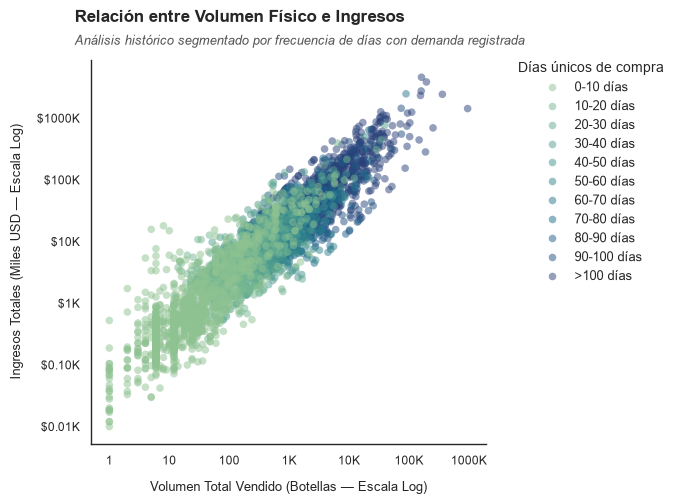

In [30]:
sns.set_theme(context = 'paper', style = 'white')

# Definir el mapa de color continuo
#cmap = sns.dark_palette('#0a428b', n_colors = 11, reverse = True)
cmap = sns.color_palette('crest', n_colors=11)

# Gráfico relplot
g = sns.relplot(
    data = analysis_01,
    x = 'volumen_total',
    y = 'sales_miles',
    hue = 'frecuencia_dias_demanda_cat',
    palette = cmap,
    aspect = 1,
    height = 5,
    alpha = 0.5,
    s = 30,
    linewidth = 0,
    legend = True
)

# Acceso al eje principal del FacetGrid
ax = g.ax

# 1. Aplicar escala logarítmica a ambos ejes
ax.set_xscale('log')
ax.set_yscale('log')

# 2. Formato numérico adaptado a los saltos de escala logarítmica
ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(
        lambda x, _: f'{x/1e3:.0f}K' if x >= 1e3 else f'{int(x)}'
    )
)

ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(
        lambda y, _: f'${y:.0f}K' if y >= 1 else f'${y:.2f}K'
    )
)

# 3. Título principal usando el contenedor de la figura (g.fig)
g.fig.suptitle(
    'Relación entre Volumen Físico e Ingresos',
    fontweight='bold',
    fontsize=12,
    x=0.12,          # Alineado a la izquierda (coincide con el eje)
    y=0.98,          # Posición vertical superior
    ha='left'
)

# 4. Descripción / Subtítulo justo debajo del título principal
g.fig.text(
    0.12,            # Misma coordenada X para mantener la alineación izquierda
    0.91,            # Ligeramente más abajo que el título principal
    'Análisis histórico segmentado por frecuencia de días con demanda registrada',
    fontsize=9,
    style='italic',
    color='#555555', # Gris sutil para diferenciarlo del título
    ha='left'
)

# Ajustar los márgenes superiores de la figura para que no se solapen los títulos
g.fig.subplots_adjust(top=0.88)

ax.set_xlabel('Volumen Total Vendido (Botellas — Escala Log)', labelpad=10)
ax.set_ylabel('Ingresos Totales (Miles USD — Escala Log)', labelpad=10)

sns.move_legend(
    g, 
    loc="upper left", 
    bbox_to_anchor=(0.75, 0.90),  
    frameon=False,               
    facecolor='white',          
    edgecolor='#cccccc',        
    title='Días únicos de compra',
    title_fontsize='10',
    fontsize='9'
)

plt.show()

In [31]:
# Eliminar variables intermedias
del (df_selected_variables, df_eliminated_variables,
    limpiar_texto_own, load_data_own, duplicados_im_desc,
    duplicados_item_no, aux, ax, cmap, g)

<h3><span style="color:#05856d">5. Resampling e imputación de 0's</span></h3>

---

El producto seleccionado para la simulación lleva la categoría **AMERICAN VODKAS (Producto: PRD_001343)**. En 115 días distintos se han generados más de 3 millones de dólares y se han vendido casi 200,000 botellas. Entonces, al aislar este producto, se sumarán todas sus ventas por día (porque en un día puede haber sido comprado por 50 tiendas distintas) y, lo más crítico: se crearán los días en los que no se vendió nada para colocarles demanda = 0.

Si se estudia el resultado, es probable observar algunos días con demanda_diaria = 0. Si no hiciéramos este paso de rellenar los ceros, el agente de AI (Deep Reinforcement Learning) creería que todos los días se vende producto. Al poner los ceros, el agente aprenderá por las malas que si pide mucho inventario en un día malo, se quedará con el producto estancado y se le cobrarán costos de almacenamiento.

In [32]:
df_01.glimpse()

Rows: 964947
Columns: 9
$ bottle_volume_ml  <f64> 750.0, 1750.0, 375.0, 50.0, 1750.0, 375.0, 375.0, 750.0, 750.0, 50.0
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ item_no           <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on       <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ pack              <i64> 12, 6, 24, 10, 6, 24, 24, 12, 12, 12
$ product_code      <str> 'PRD_000917', 'PRD_000180', 'PRD_000176', 'PRD_000156', 'PRD_001524', 'PRD_001520', 'PRD_000487', 'PRD_000935', 'PRD_000906

In [33]:
df_02 = (
    df_01
    .filter(pl.col('product_code') == 'PRD_001343')
    .group_by('ordered_on')
    .agg( pl.sum('sales_bottles').alias('demanda_diaria'),
          pl.sum('sales_dollars').alias('ingresos_diarios'),
          pl.col('pack').drop_nulls().unique() )
)

aux_calendario = pl.DataFrame({
    'ordered_on': pl.date_range(
        start = pl.date(year = 2026, month = 1, day = 1),
        end = df_02['ordered_on'].max(),
        interval = '1d',
        eager = True) })

df_02 = (
    aux_calendario
    .join( other = df_02, on = 'ordered_on', how = 'left', validate = '1:1')
    # Si ese día no hubo ventas, la demanda y el ingreso son 0
    .with_columns([ pl.col('demanda_diaria').fill_null(0),
                    pl.col('ingresos_diarios').fill_null(0) ]) )


df_03 = (
    df_01
    .filter(pl.col('product_code') == 'PRD_001343')
    .select( (pl.sum('sales_dollars') / pl.sum('sales_bottles')).alias('precio_medio'),
             pl.col('pack').drop_nulls().unique() ) )

del aux_calendario

print('-----------------------------------------------------')
print(f'DÍAS TOTALES DE SIMULACIÓN (df_02): {df_02.height}')
df_02.sample(n = 5, seed = 5).show()

print('-----------------------------------------------------')
print('PRECIOS UNITARIOS (df_03)')
df_03.show()


-----------------------------------------------------
DÍAS TOTALES DE SIMULACIÓN (df_02): 150
shape: (5, 4)
┌────────────┬────────────────┬──────────────────┬───────────┐
│ ordered_on ┆ demanda_diaria ┆ ingresos_diarios ┆ pack      │
│ ---        ┆ ---            ┆ ---              ┆ ---       │
│ date       ┆ i64            ┆ f64              ┆ list[i64] │
╞════════════╪════════════════╪══════════════════╪═══════════╡
│ 2026-02-12 ┆ 2231           ┆ 44084.56         ┆ [12]      │
│ 2026-03-31 ┆ 964            ┆ 19048.64         ┆ [12]      │
│ 2026-01-15 ┆ 1997           ┆ 39455.0          ┆ [12]      │
│ 2026-01-09 ┆ 1590           ┆ 31411.0          ┆ [12]      │
│ 2026-03-21 ┆ 0              ┆ 0.0              ┆ null      │
└────────────┴────────────────┴──────────────────┴───────────┘
-----------------------------------------------------
PRECIOS UNITARIOS (df_03)
shape: (1, 2)
┌──────────────┬──────┐
│ precio_medio ┆ pack │
│ ---          ┆ ---  │
│ f64          ┆ i64  │
╞════════

In [ ]:
from s_01_functions import eoq_baseline

eo = eoq_baseline(
    df_demanda = df_02,
    df_precio = df_03,
    dias_simulacion = 150,
    dias_year = 365,
    costo_pedido_S = 50,
    tasa_mantenimiento_i = 0.20 )

print(f'El resultado del lote económico es: {eoq_baseline}')

-------------------------------------------------------
RESULTADOS DEL MODELO BASE (EOQ)
-------------------------------------------------------
Demanda Anual Estimada (D)       : 476,111 botellas
Costo de Mantenimiento Anual (H) : $3.95 por botella
Costo Fijo por Pedido (S)        : $50.00
EOQ Óptimo Teórico               : 3,471 botellas
EOQ Ajustado a Lotes (Acción)    : 289 cajas (packs de 12)
-------------------------------------------------------
El resultado del lote económico es: 289.0


Prueba de humo

In [12]:
# Importar la clase desde tu script modular
from s_01_stock_env import EntornoInventario

# 1. Extraer los parámetros de precio y tamaño de lote
precio_u = df_03['precio_medio'][0]

pack_u = df_03['pack'][0]
if isinstance(pack_u, (list, pl.Series)):
    pack_u = pack_u[0]

# 2. Instanciar el entorno con tus datos reales procesados
env = EntornoInventario(
    df_demanda=df_02,
    precio_unitario=precio_u,
    tamano_pack=pack_u,
    max_cajas_pedido=100
)

# 3. Reiniciar el entorno para comenzar el episodio en el Día 0
estado_actual, info = env.reset()
print(f"Estado inicial: Inventario = {estado_actual[0]} botellas\n")

# 4. Simular los primeros 5 días con un Agente Aleatorio
for dia in range(5):
    # El agente elige una acción al azar usando el action_space que definiste (0 a 100)
    accion_aleatoria = env.action_space.sample()
    
    # El entorno procesa la decisión y avanza un día
    siguiente_estado, recompensa, terminado, truncado, info = env.step(accion_aleatoria)
    
    # Mostrar el reporte del día
    print(f"--- DÍA {dia + 1} ---")
    print(f"📦 Acción del agente : Pidió {accion_aleatoria} cajas")
    print(f"🛒 Ventas reales     : {info['ventas']} botellas")
    print(f"⚠️ Quiebre de stock  : {info['quiebre']} botellas")
    print(f"💰 Recompensa Neta   : ${recompensa:,.2f}")
    print(f"🏭 Inventario final  : {siguiente_estado[0]} botellas\n")
    
    if terminado:
        print("El episodio ha terminado.")
        break

# Cerrar el entorno por buenas prácticas
env.close()
# 1. Instanciar el entorno con tus datos reales procesados
precio_u = df_03['precio_medio'][0]
pack_u = df_03['pack'][0]

env = EntornoInventario(
    df_demanda=df_02,
    precio_unitario=precio_u,
    tamano_pack=pack_u,
    max_cajas_pedido=100
)

# 2. Reiniciar el entorno para comenzar el episodio en el Día 0
estado_actual, info = env.reset()
print(f"Estado inicial: Inventario = {estado_actual[0]} botellas\\n")

# 3. Simular los primeros 5 días con un Agente Aleatorio
for dia in range(5):
    # El agente elige una acción al azar usando el action_space que definiste (0 a 100)
    accion_aleatoria = env.action_space.sample()
    
    # El entorno procesa la decisión y avanza un día
    siguiente_estado, recompensa, terminado, truncado, info = env.step(accion_aleatoria)
    
    # Mostrar el reporte del día
    print(f"--- DÍA {dia + 1} ---")
    print(f"📦 Acción del agente : Pidió {accion_aleatoria} cajas")
    print(f"🛒 Ventas reales     : {info['ventas']} botellas")
    print(f"⚠️ Quiebre de stock  : {info['quiebre']} botellas")
    print(f"💰 Recompensa Neta   : ${recompensa:,.2f}")
    print(f"🏭 Inventario final  : {siguiente_estado[0]} botellas\\n")
    
    if terminado:
        print("El episodio ha terminado.")
        break

# Cerrar el entorno por buenas priniiácticas
env.close()

Estado inicial: Inventario = 0.0 botellas

--- DÍA 1 ---
📦 Acción del agente : Pidió 35 cajas
🛒 Ventas reales     : 0 botellas
⚠️ Quiebre de stock  : 0 botellas
💰 Recompensa Neta   : $-50.00
🏭 Inventario final  : 0.0 botellas

--- DÍA 2 ---
📦 Acción del agente : Pidió 41 cajas
🛒 Ventas reales     : 0 botellas
⚠️ Quiebre de stock  : 3679 botellas
💰 Recompensa Neta   : $-7,408.00
🏭 Inventario final  : 0.0 botellas

--- DÍA 3 ---
📦 Acción del agente : Pidió 7 cajas
🛒 Ventas reales     : 0 botellas
⚠️ Quiebre de stock  : 0 botellas
💰 Recompensa Neta   : $-50.00
🏭 Inventario final  : 0.0 botellas

--- DÍA 4 ---
📦 Acción del agente : Pidió 40 cajas
🛒 Ventas reales     : 68 botellas
⚠️ Quiebre de stock  : 0 botellas
💰 Recompensa Neta   : $1,290.09
🏭 Inventario final  : 352.0 botellas

--- DÍA 5 ---
📦 Acción del agente : Pidió 84 cajas
🛒 Ventas reales     : 844 botellas
⚠️ Quiebre de stock  : 2834 botellas
💰 Recompensa Neta   : $10,958.54
🏭 Inventario final  : 0.0 botellas

Estado inicial: Inv

In [ ]:
# Importar la librería de Inteligencia Artificial
# Importar entorno personalizado
from s_01_stock_env import EntornoInventario
from stable_baselines3 import PPO

# 1. Extraer los parámetros de precio y tamaño de lote desde los DataFrames
precio_u = df_03['precio_medio'][0]

pack_u = df_03['pack'][0]
if isinstance(pack_u, (list, pl.Series)):
    pack_u = pack_u[0]

# 2. Instanciar el entorno de entrenamiento
env = EntornoInventario(
    df_demanda = df_02,
    precio_unitario = precio_u,
    tamano_pack = pack_u,
    max_cajas_pedido = 100,
    ventana_historica = 7
)

# 3. Crear el cerebro del Agente (Red Neuronal)
print('🧠 Instanciando la Red Neuronal con PPO...')
modelo_ppo = PPO('MlpPolicy', env, verbose = 1, seed = 42)

# 4. Iniciar el Entrenamiento (Aprendizaje Profundo)
# 150,000 timesteps equivalen a jugar 1,000 años de simulación (150k / 150 días)
print('🚀 Iniciando el entrenamiento. Esto puede tomar unos minutos...')
modelo_ppo.learn(total_timesteps = 150000)

# 5. Guardar el modelo entrenado en tu disco local
modelo_ppo.save('agente_inventario_ppo')
print('✅ ¡Entrenamiento finalizado y modelo guardado exitosamente!')

# Cerrar el entorno
env.close()

🧠 Instanciando la Red Neuronal con PPO...
Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
🚀 Iniciando el entrenamiento. Esto puede tomar unos minutos...
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 150      |
|    ep_rew_mean     | 1.52e+06 |
| time/              |          |
|    fps             | 3645     |
|    iterations      | 1        |
|    time_elapsed    | 0        |
|    total_timesteps | 2048     |
---------------------------------
-------------------------------------------
| rollout/                |               |
|    ep_len_mean          | 150           |
|    ep_rew_mean          | 1.52e+06      |
| time/                   |               |
|    fps                  | 2526          |
|    iterations           | 2             |
|    time_elapsed         | 1             |
|    total_timesteps      | 4096          |
| train/                  |               |
|    approx_kl       

In [14]:
from stable_baselines3 import PPO

# 1. Cargar el modelo entrenado desde el disco
print("Cargando el agente entrenado...")
agente_inteligente = PPO.load('agente_inventario_ppo')

# 2. Reiniciar el entorno para una prueba limpia
estado, info = env.reset()

# 3. Crear listas para guardar la historia y graficar después
historial_inventario = []
historial_acciones = []
historial_recompensas = []
historial_quiebres = []

terminado = False
truncado = False
dia = 1

print("\n🚀 Iniciando simulación con el Agente Inteligente...\n")

# 4. El bucle de evaluación
while not (terminado or truncado):
    # La IA observa el estado (inventario + ventana histórica) y decide la mejor acción
    # deterministic=True obliga a la red a tomar su mejor decisión, eliminando el azar
    accion, _estados_internos = agente_inteligente.predict(estado, deterministic=True)
    
    # Extraemos el valor entero de la acción
    accion_entera = int(accion)
    
    # El entorno procesa la decisión
    estado, recompensa, terminado, truncado, info = env.step(accion_entera)
    
    # Guardamos los resultados para el análisis
    historial_inventario.append(estado[0])
    historial_acciones.append(accion_entera)
    historial_recompensas.append(recompensa)
    historial_quiebres.append(info['quiebre'])
    
    dia += 1

# 5. Resumen Financiero y Logístico
recompensa_total = sum(historial_recompensas)
total_quiebres = sum(historial_quiebres)
cajas_pedidas_total = sum(historial_acciones)

print("-" * 50)
print("🏆 RESULTADOS FINALES DEL MODELO DRL (PPO)")
print("-" * 50)
print(f"💰 Rentabilidad Total Acumulada : ${recompensa_total:,.2f}")
print(f"📦 Total de Cajas Pedidas       : {cajas_pedidas_total:,.0f} cajas")
print(f"⚠️ Quiebres de Stock Totales    : {total_quiebres:,.0f} botellas perdidas")
print("-" * 50)

Cargando el agente entrenado...

🚀 Iniciando simulación con el Agente Inteligente...

--------------------------------------------------
🏆 RESULTADOS FINALES DEL MODELO DRL (PPO)
--------------------------------------------------
💰 Rentabilidad Total Acumulada : $2,737,140.12
📦 Total de Cajas Pedidas       : 12,314 cajas
⚠️ Quiebres de Stock Totales    : 51,459 botellas perdidas
--------------------------------------------------


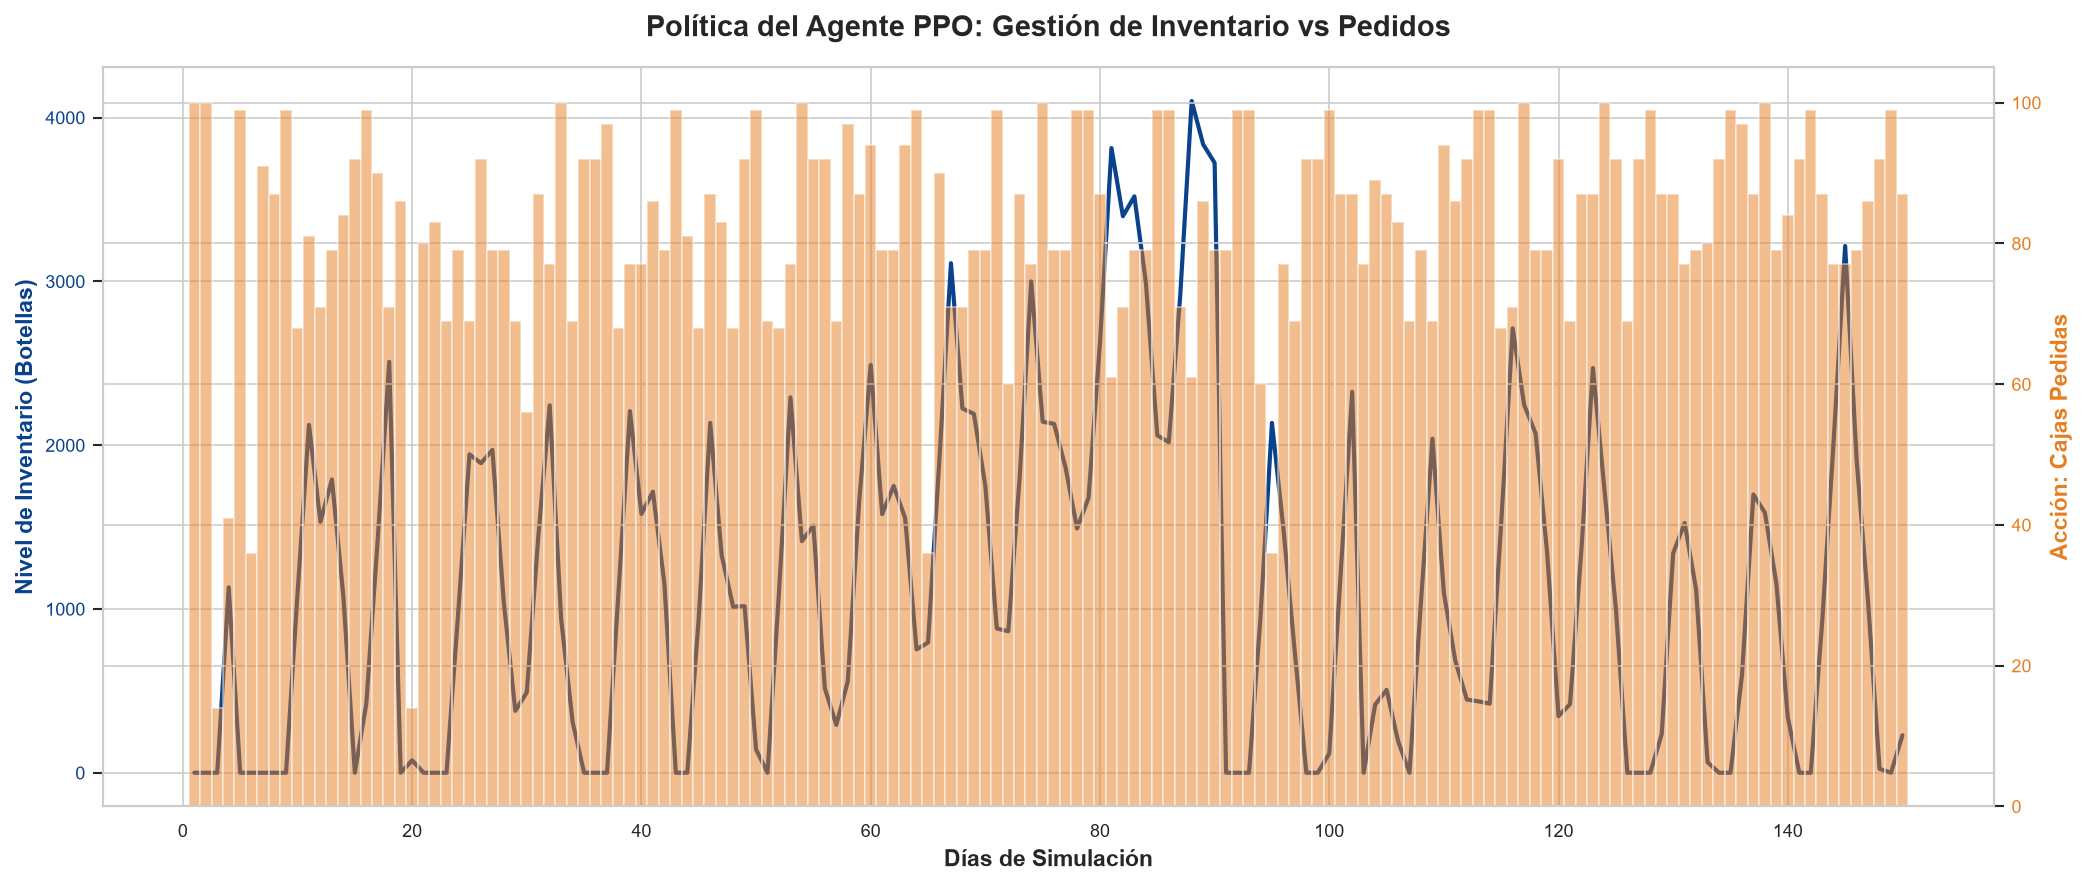

In [17]:

# 1. Crear un DataFrame con el historial que acabamos de recolectar
df_resultados = pd.DataFrame({
    'Día': range(1, len(historial_inventario) + 1),
    'Inventario': historial_inventario,
    'Cajas_Pedidas': historial_acciones,
    'Quiebres': historial_quiebres
})

# 2. Configurar el estilo del gráfico
sns.set_theme(context='paper', style='whitegrid')
fig, ax1 = plt.subplots(figsize=(14, 6))

# 3. Graficar el Nivel de Inventario (Línea Azul)
color_inv = '#0a428b'
ax1.set_xlabel('Días de Simulación', fontweight='bold', fontsize=11)
ax1.set_ylabel('Nivel de Inventario (Botellas)', color=color_inv, fontweight='bold', fontsize=11)
ax1.plot(df_resultados['Día'], df_resultados['Inventario'], color=color_inv, linewidth=2, label='Inventario Disponible')
ax1.tick_params(axis='y', labelcolor=color_inv)

# 4. Crear un segundo eje Y para graficar los pedidos del Agente (Barras Naranjas)
ax2 = ax1.twinx()  
color_acc = '#e67e22'
ax2.set_ylabel('Acción: Cajas Pedidas', color=color_acc, fontweight='bold', fontsize=11)
ax2.bar(df_resultados['Día'], df_resultados['Cajas_Pedidas'], color=color_acc, alpha=0.5, width=1.0, label='Cajas Pedidas')
ax2.tick_params(axis='y', labelcolor=color_acc)

# 5. Estética final
plt.title('Política del Agente PPO: Gestión de Inventario vs Pedidos', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout() 
plt.show()

In [22]:
# 1. Reiniciar el entorno para evaluar el Baseline EOQ
estado, info = env.reset()
terminado = False
truncado = False

historial_recompensas_eoq = []
historial_quiebres_eoq = []
historial_acciones_eoq = []

# Definir un Punto de Reorden simple (Demanda promedio diaria * Lead Time)
demanda_promedio = df_02['demanda_diaria'].mean()
punto_reorden = demanda_promedio * env.L

while not (terminado or truncado):
    inventario_actual = estado[0]
    
    # Lógica Tradicional: Si el inventario cae por debajo del punto de reorden, 
    # pedimos el lote económico (289 cajas calculadas previamente)
    if inventario_actual <= punto_reorden:
        accion_eoq = 289
    else:
        accion_eoq = 0
        
    estado, recompensa, terminado, truncado, info = env.step(accion_eoq)
    
    historial_recompensas_eoq.append(recompensa)
    historial_quiebres_eoq.append(info['quiebre'])
    historial_acciones_eoq.append(accion_eoq)

# 2. Consolidar los resultados del EOQ
rentabilidad_eoq = sum(historial_recompensas_eoq)
quiebres_eoq = sum(historial_quiebres_eoq)
cajas_eoq = sum(historial_acciones_eoq)

# 3. Crear y mostrar la tabla comparativa final
tabla_comparativa = pd.DataFrame({
    'Métrica Logística': [
        'Rentabilidad Total (USD)', 
        'Total Cajas Pedidas', 
        'Quiebres de Stock (Botellas)'
    ],
    'Baseline Tradicional (EOQ)': [
        f"${rentabilidad_eoq:,.2f}", 
        f"{cajas_eoq:,.0f}", 
        f"{quiebres_eoq:,.0f}"
    ],
    'Agente Inteligente (PPO)': [
        f"${recompensa_total:,.2f}", 
        f"{cajas_pedidas_total:,.0f}", 
        f"{total_quiebres:,.0f}"
    ]
})

print("📊 COMPARATIVA FINAL: EOQ vs PPO")
print(tabla_comparativa)

📊 COMPARATIVA FINAL: EOQ vs PPO
              Métrica Logística Baseline Tradicional (EOQ)  \
0      Rentabilidad Total (USD)              $3,143,961.98   
1           Total Cajas Pedidas                     14,450   
2  Quiebres de Stock (Botellas)                     32,666   

  Agente Inteligente (PPO)  
0            $2,737,140.12  
1                   12,314  
2                   51,459  


In [23]:
from stable_baselines3 import PPO

print('🧠 Instanciando la Red Neuronal PPO v2.0 (Alta Exploración)...')
# Añadimos ent_coef para forzar la exploración y reducimos un poco el learning_rate para mayor estabilidad
modelo_ppo_v2 = PPO(
    'MlpPolicy', 
    env, 
    verbose=1, 
    seed=42, 
    ent_coef=0.01, 
    learning_rate=0.0002
)

# Aumentamos dramáticamente el tiempo de experiencia del agente
print('🚀 Iniciando el entrenamiento extendido (1,000,000 timesteps)...')
modelo_ppo_v2.learn(total_timesteps=1000000)

# Guardamos este nuevo cerebro
modelo_ppo_v2.save('agente_inventario_ppo_v2')
print('✅ ¡Entrenamiento intensivo finalizado!')

🧠 Instanciando la Red Neuronal PPO v2.0 (Alta Exploración)...
Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
🚀 Iniciando el entrenamiento extendido (1,000,000 timesteps)...
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 150      |
|    ep_rew_mean     | 1.52e+06 |
| time/              |          |
|    fps             | 3540     |
|    iterations      | 1        |
|    time_elapsed    | 0        |
|    total_timesteps | 2048     |
---------------------------------
-------------------------------------------
| rollout/                |               |
|    ep_len_mean          | 150           |
|    ep_rew_mean          | 1.52e+06      |
| time/                   |               |
|    fps                  | 2384          |
|    iterations           | 2             |
|    time_elapsed         | 1             |
|    total_timesteps      | 4096          |
| train/                  |               |


In [29]:
import pandas as pd
from stable_baselines3 import PPO

# 1. Cargar el NUEVO modelo entrenado (v2.0)
print("Cargando el Agente Inteligente v2.0...")
agente_inteligente_v2 = PPO.load('agente_inventario_ppo_v2')

# 2. Reiniciar el entorno para una prueba limpia
estado, info = env.reset()

historial_recompensas_v2 = []
historial_quiebres_v2 = []
historial_acciones_v2 = []

terminado = False
truncado = False

print("\n🚀 Iniciando simulación de evaluación...\n")

# 3. Bucle de evaluación determinista
while not (terminado or truncado):
    # Pedimos al nuevo modelo que tome la mejor decisión posible
    accion, _ = agente_inteligente_v2.predict(estado, deterministic=True)
    accion_entera = int(accion)
    
    # El entorno procesa la decisión
    estado, recompensa, terminado, truncado, info = env.step(accion_entera)
    
    # Guardamos los resultados
    historial_recompensas_v2.append(recompensa)
    historial_quiebres_v2.append(info['quiebre'])
    historial_acciones_v2.append(accion_entera)

# 4. Consolidar resultados del PPO v2.0
rentabilidad_v2 = sum(historial_recompensas_v2)
quiebres_v2 = sum(historial_quiebres_v2)
cajas_v2 = sum(historial_acciones_v2)

# 5. Cargar los datos del EOQ que calculaste en la prueba anterior
rentabilidad_eoq = 3143961.98
cajas_eoq = 14450
quiebres_eoq = 32666

# 6. Generar la tabla comparativa definitiva
tabla_final = pd.DataFrame({
    'Métrica Logística': [
        'Rentabilidad Total (USD)', 
        'Total Cajas Pedidas', 
        'Quiebres de Stock (Botellas)'
    ],
    'Baseline EOQ': [
        f"${rentabilidad_eoq:,.2f}", 
        f"{cajas_eoq:,.0f}", 
        f"{quiebres_eoq:,.0f}"
    ],
    'Agente PPO v2.0': [
        f"${rentabilidad_v2:,.2f}", 
        f"{cajas_v2:,.0f}", 
        f"{quiebres_v2:,.0f}"
    ]
})

print("📊 COMPARATIVA DEFINITIVA: EOQ vs PPO v2.0")
print(tabla_final)

Cargando el Agente Inteligente v2.0...

🚀 Iniciando simulación de evaluación...

📊 COMPARATIVA DEFINITIVA: EOQ vs PPO v2.0
              Métrica Logística   Baseline EOQ Agente PPO v2.0
0      Rentabilidad Total (USD)  $3,143,961.98   $3,352,410.35
1           Total Cajas Pedidas         14,450          14,771
2  Quiebres de Stock (Botellas)         32,666          22,976
